# Experiment 1 — Baseline: DINOv2 ViT-B/14 Linear Probing on Brain Tumor MRI

This notebook establishes the baseline linear probing performance of **DINOv2 ViT-B/14** (`MHRDYN7/dinov2_vitb14`) on the **Cheng Brain Tumor MRI** 3-class classification benchmark (Meningioma, Glioma, Pituitary).

Following the evaluation protocol established by **Baharoon et al. (2024, arXiv:2312.02366v4)** (*Evaluating General Purpose Vision Foundation Models for Medical Image Analysis: An Experimental Study of DINOv2 on Radiology Benchmarks*), the entire pretrained vision transformer encoder remains completely frozen. Only a lightweight linear classification head is trained on top of the 768-dimensional `[CLS]` token representations using Stochastic Gradient Descent (SGD) and Cross-Entropy Loss.

Our primary objective is to replicate the published linear probing AUROC benchmark target of **0.972**.

### Base Paper Benchmark Reference Results (Cheng Brain Tumor MRI)

| Architecture | Paradigm | Parameters | AUROC | Source |
|---|---|---|---|---|
| Supervised DenseNet201 | Supervised Full Fine-Tuning | 20M | 0.960 | Baharoon et al. (2024) |
| Supervised ViT-L/16 | Supervised Full Fine-Tuning | 304M | 0.975 | Baharoon et al. (2024) |
| DINOv2 ViT-S/14 | Self-Supervised Linear Probing | 22M | 0.962 | Baharoon et al. (2024) |
| **DINOv2 ViT-B/14 (Target)** | **Self-Supervised Linear Probing** | **86M** | **0.972** | **Baharoon et al. (2024)** |
| DINOv2 ViT-L/14 | Self-Supervised Linear Probing | 304M | 0.974 | Baharoon et al. (2024) |
| DINOv2 ViT-g/14 | Self-Supervised Linear Probing | 1,100M | **0.976** | Baharoon et al. (2024) |

In [4]:
import os
from pathlib import Path
import subprocess
import sys
import google

repo_dir: Path | None = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "src").is_dir() and (candidate / "requirements.txt").is_file():
        repo_dir = candidate
        break

if repo_dir is None:
    repo_url = "https://github.com/RudhanLodhi/DinoV2_PEFT.git"
    repo_dir = Path.cwd() / "DinoV2B"
    subprocess.run(["git", "clone", repo_url, str(repo_dir)], check=True)

os.chdir(repo_dir)
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", ".", "-r", "requirements.txt", "opencv-python-headless", "requests", "-q"],
    check=False,
)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR: Path = Path("/content/drive/MyDrive/dinov2_peft/brain_tumor")
except ImportError:
    CHECKPOINT_DIR = Path("checkpoints/brain_tumor")

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Repository: {repo_dir}")
print(f"Checkpoint directory established at: {CHECKPOINT_DIR}")

Mounted at /content/drive
Repository: /content/DinoV2B
Checkpoint directory established at: /content/drive/MyDrive/dinov2_peft/brain_tumor


## 1. Hyperparameter Configuration

Hyperparameter specifications adhering to the exact protocol of Baharoon et al. (2024, arXiv:2312.02366v4):
- **Image Resolution:** 224 x 224 pixels
- **Batch Size:** 128
- **Optimizer:** SGD with momentum = 0.9
- **Learning Rate:** 0.01 (selected by Baharoon et al. from grid {1e-1, 5e-2, 1e-2, 5e-3, 1e-3, 5e-4, 1e-4, 1e-5})
- **Epochs:** 20
- **Dropout:** 0.1
- **Preprocessing:** MRI pixel intensity percentile clipping at [5th, 95th percentile]
- **Data Augmentation:** RandomResizedCrop(224, scale=(0.75, 1.0)) + RandomHorizontalFlip(p=0.5)

In [14]:
"""
Hyperparameter dictionary, class mappings, and reference baseline figures.
Establishes the Baharoon et al. (2024) training hyperparameters and target metrics.
"""
from typing import Any

HPARAMS: dict[str, Any] = {
    "model_id": "facebook/dinov2-base",
    "image_size": 224,
    "batch_size": 128,
    "optimizer": "SGD",
    "sgd_momentum": 0.9,
    "learning_rate": 1e-2,
    "epochs": 20,
    "dropout": 0.1,
    "num_workers": 2,
    "seed": 42,
    "mri_clip_percentile_low": 5.0,
    "mri_clip_percentile_high": 95.0,
    "crop_scale_min": 0.75,
    "crop_scale_max": 1.0,
    "flip_prob": 0.5,
    "normalize_mean": [0.485, 0.456, 0.406],
    "normalize_std": [0.229, 0.224, 0.225],
}

CLASS_NAMES: dict[int, str] = {
    0: "Meningioma",
    1: "Glioma",
    2: "Pituitary",
}
CLASS_LIST: list[str] = [CLASS_NAMES[i] for i in range(3)]
NUM_CLASSES: int = 3

BASE_PAPER_RESULTS: dict[str, dict[str, Any]] = {
    "Supervised DenseNet201": {
        "auroc": 0.960,
        "method": "Full Fine-Tuning",
        "architecture": "DenseNet201",
    },
    "Supervised ViT-L/16": {
        "auroc": 0.975,
        "method": "Full Fine-Tuning",
        "architecture": "ViT-L/16",
    },
    "DINOv2 ViT-S/14": {
        "auroc": 0.962,
        "method": "Linear Probe",
        "architecture": "ViT-S/14",
    },
    "DINOv2 ViT-B/14 (Target)": {
        "auroc": 0.972,
        "method": "Linear Probe",
        "architecture": "ViT-B/14",
    },
    "DINOv2 ViT-L/14": {
        "auroc": 0.974,
        "method": "Linear Probe",
        "architecture": "ViT-L/14",
    },
    "DINOv2 ViT-g/14": {
        "auroc": 0.976,
        "method": "Linear Probe",
        "architecture": "ViT-g/14",
    },
}

print(f"Target Model: {HPARAMS['model_id']}")
print(f"Number of Classes: {NUM_CLASSES} ({', '.join(CLASS_LIST)})")
print(
    f"Batch Size: {HPARAMS['batch_size']} | Optimizer: {HPARAMS['optimizer']} "
    f"(lr={HPARAMS['learning_rate']}, momentum={HPARAMS['sgd_momentum']}) | "
    f"Epochs: {HPARAMS['epochs']}"
)

Target Model: facebook/dinov2-base
Number of Classes: 3 (Meningioma, Glioma, Pituitary)
Batch Size: 128 | Optimizer: SGD (lr=0.01, momentum=0.9) | Epochs: 20


## 2. Dataset Loading

The Cheng Brain Tumor MRI dataset contains 3,064 T1-weighted contrast-enhanced brain MRI slices (512x512) from 233 patients. It covers three tumor types:
- **0:** Meningioma
- **1:** Glioma
- **2:** Pituitary

The dataset manifest is stored in Ultralytics NDJSON format at `cheng-brain-tumor-mri-detection.ndjson`. Each line represents an image slice record:
- `file`: Relative image filename on disk (e.g., `2295.jpg`).
- `split`: Pre-assigned patient-level split (`train`, `val`, or `test`), ensuring zero patient overlap across splits.
- `url`: Direct CDN download URL for the slice image.
- `annotations.boxes`: YOLO-format bounding box annotations `[class_id, x_center, y_center, width, height]`. The first value identifies the tumor pathology index.

Train split images: 2,133
Val split images:   651
Test split images:  280
Total dataset size: 3,064 images


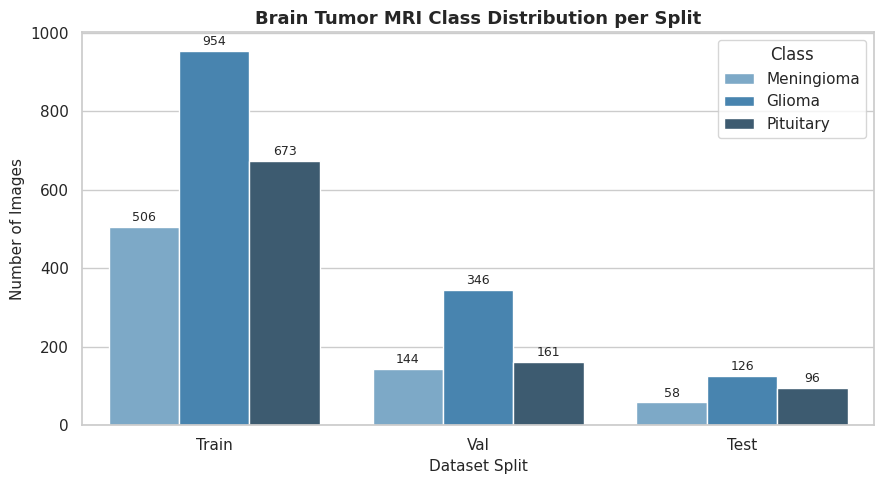

In [6]:
"""
Parse dataset manifest and inspect class distribution across splits.
Loads records from the NDJSON manifest and renders a grouped bar chart.
"""
from collections import Counter
from pathlib import Path
from typing import Any
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.data.brain_tumor_dataset import load_ndjson_records

NDJSON_PATH: Path = Path("cheng-brain-tumor-mri-detection.ndjson")
train_recs, val_recs, test_recs = load_ndjson_records(NDJSON_PATH)

print(f"Train split images: {len(train_recs):,}")
print(f"Val split images:   {len(val_recs):,}")
print(f"Test split images:  {len(test_recs):,}")
print(f"Total dataset size: {len(train_recs) + len(val_recs) + len(test_recs):,} images")

split_records_map: dict[str, list[dict[str, Any]]] = {
    "Train": train_recs,
    "Val": val_recs,
    "Test": test_recs,
}

chart_data: list[dict[str, Any]] = []
for split_name, recs in split_records_map.items():
    counts: Counter[int] = Counter(int(r["label"]) for r in recs)
    for class_id in range(NUM_CLASSES):
        chart_data.append(
            {
                "Split": split_name,
                "Class": CLASS_NAMES[class_id],
                "Count": counts.get(class_id, 0),
            }
        )

df_dist: pd.DataFrame = pd.DataFrame(chart_data)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=df_dist, x="Split", y="Count", hue="Class", palette="Blues_d", ax=ax)
ax.set_title("Brain Tumor MRI Class Distribution per Split", fontsize=13, fontweight="bold")
ax.set_xlabel("Dataset Split", fontsize=11)
ax.set_ylabel("Number of Images", fontsize=11)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 2),
            textcoords="offset points",
        )

plt.tight_layout()
plt.show()

In [8]:
"""
Download MRI images from Ultralytics CDN URLs in the NDJSON manifest.
Saves images locally to data/brain_tumor/images with progress reporting and error handling.
"""
from io import BytesIO
import json
from pathlib import Path
from typing import Any
from PIL import Image
import requests
from tqdm.auto import tqdm

IMAGE_ROOT: Path = Path("data/brain_tumor/images")
IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

def download_images_from_ndjson(
    ndjson_path: str | Path,
    image_root: str | Path,
    max_failures: int = 50,
) -> Path:
    """Download all images referenced in NDJSON manifest to local disk.

    Skips images already present on disk. Raises RuntimeError if too many
    consecutive downloads fail (indicates expired CDN URLs).

    Args:
        ndjson_path: Path to the NDJSON manifest file.
        image_root: Local directory to save downloaded images.
        max_failures: Maximum allowed consecutive download failures.

    Returns:
        Path to image root directory.
    """
    records: list[dict[str, Any]] = []
    with open(ndjson_path, "r", encoding="utf-8") as f:
        for line in f:
            line_str: str = line.strip()
            if not line_str:
                continue
            r: dict[str, Any] = json.loads(line_str)
            if r.get("type") == "image" and r.get("url"):
                records.append(r)

    failures: int = 0
    target_root: Path = Path(image_root)
    for r in tqdm(records, desc="Downloading MRI images"):
        dest: Path = target_root / r["file"]
        if dest.exists():
            failures = 0
            continue
        try:
            resp = requests.get(r["url"], timeout=15)
            resp.raise_for_status()
            img: Image.Image = Image.open(BytesIO(resp.content)).convert("RGB")
            img.save(dest)
            failures = 0
        except Exception:
            failures += 1
            if failures >= max_failures:
                raise RuntimeError(
                    f"Too many consecutive download failures ({max_failures}). "
                    "CDN URLs in the NDJSON may be expired. "
                    "Please regenerate the NDJSON file from the Ultralytics platform: "
                    "https://platform.ultralytics.com/aravinthan-s/datasets/cheng-brain-tumor-mri-detection"
                )
    return target_root

download_images_from_ndjson(NDJSON_PATH, IMAGE_ROOT)
print(f"Images ready in: {IMAGE_ROOT}")
print(f"Total images on disk: {len(list(IMAGE_ROOT.glob('*.jpg'))):,}")

Images ready in: data/brain_tumor/images
Total images on disk: 3,064


In [9]:
"""
MRI intensity preprocessing: percentile clipping at [5th, 95th] as per Baharoon et al. (2024).
This is the paper's standard MRI preprocessing before DINOv2 feature extraction.
"""
import numpy as np
from PIL import Image

class MRIPercentileClip:
    """Applies intensity percentile clipping to MRI images.

    Clips pixel intensities to the [low_pct, high_pct] percentile range and
    rescales to [0, 255]. This reduces the influence of extreme intensity values
    common in MRI acquisitions. Per Baharoon et al. (2024): clip to [5th, 95th percentile].
    """

    def __init__(self, low_pct: float = 5.0, high_pct: float = 95.0) -> None:
        """Initialises the percentile clipper.

        Args:
            low_pct: Lower percentile boundary (0-100).
            high_pct: Upper percentile boundary (0-100).
        """
        self.low_pct: float = low_pct
        self.high_pct: float = high_pct

    def __call__(self, img: Image.Image) -> Image.Image:
        """Applies percentile clipping and rescales to [0, 255] uint8.

        Args:
            img: Input PIL Image (any mode, converted to array for processing).

        Returns:
            Preprocessed PIL RGB Image with clipped intensities.
        """
        arr: np.ndarray = np.array(img, dtype=np.float32)
        lo: float = float(np.percentile(arr, self.low_pct))
        hi: float = float(np.percentile(arr, self.high_pct))
        if hi > lo:
            arr = np.clip(arr, lo, hi)
            arr = (arr - lo) / (hi - lo) * 255.0
        arr = arr.clip(0, 255).astype(np.uint8)
        return Image.fromarray(arr).convert("RGB")

In [10]:
"""
Image transformation pipelines for training, validation, and evaluation.
Implements the paper's augmentation protocol: percentile clipping, random resized crop,
horizontal flip, and ImageNet normalization.
"""
from torchvision import transforms

def build_brain_tumor_transforms(
    image_size: int = 224,
    mean: list[float] | None = None,
    std: list[float] | None = None,
    low_pct: float = 5.0,
    high_pct: float = 95.0,
) -> tuple[transforms.Compose, transforms.Compose]:
    """Constructs training and validation transforms following Baharoon et al. (2024).

    Args:
        image_size: Target square image dimension (default 224).
        mean: Normalization channel means.
        std: Normalization channel standard deviations.
        low_pct: Lower clipping percentile for MRI intensities.
        high_pct: Upper clipping percentile for MRI intensities.

    Returns:
        Tuple of (train_transforms, val_transforms).
    """
    norm_mean: list[float] = mean if mean is not None else [0.485, 0.456, 0.406]
    norm_std: list[float] = std if std is not None else [0.229, 0.224, 0.225]

    train_tf = transforms.Compose(
        [
            MRIPercentileClip(low_pct=low_pct, high_pct=high_pct),
            transforms.RandomResizedCrop(
                image_size,
                scale=(HPARAMS["crop_scale_min"], HPARAMS["crop_scale_max"]),
                interpolation=transforms.InterpolationMode.BICUBIC,
            ),
            transforms.RandomHorizontalFlip(p=HPARAMS["flip_prob"]),
            transforms.ToTensor(),
            transforms.Normalize(mean=norm_mean, std=norm_std),
        ]
    )

    val_tf = transforms.Compose(
        [
            MRIPercentileClip(low_pct=low_pct, high_pct=high_pct),
            transforms.Resize(256, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.CenterCrop(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=norm_mean, std=norm_std),
        ]
    )

    return train_tf, val_tf

train_transforms, val_transforms = build_brain_tumor_transforms(
    image_size=HPARAMS["image_size"],
    mean=HPARAMS["normalize_mean"],
    std=HPARAMS["normalize_std"],
    low_pct=HPARAMS["mri_clip_percentile_low"],
    high_pct=HPARAMS["mri_clip_percentile_high"],
)
print("Train and Validation transforms constructed successfully.")

Train and Validation transforms constructed successfully.


Train Dataset: 2,133 samples (17 batches)
Val Dataset:   651 samples (6 batches)
Test Dataset:  280 samples (3 batches)


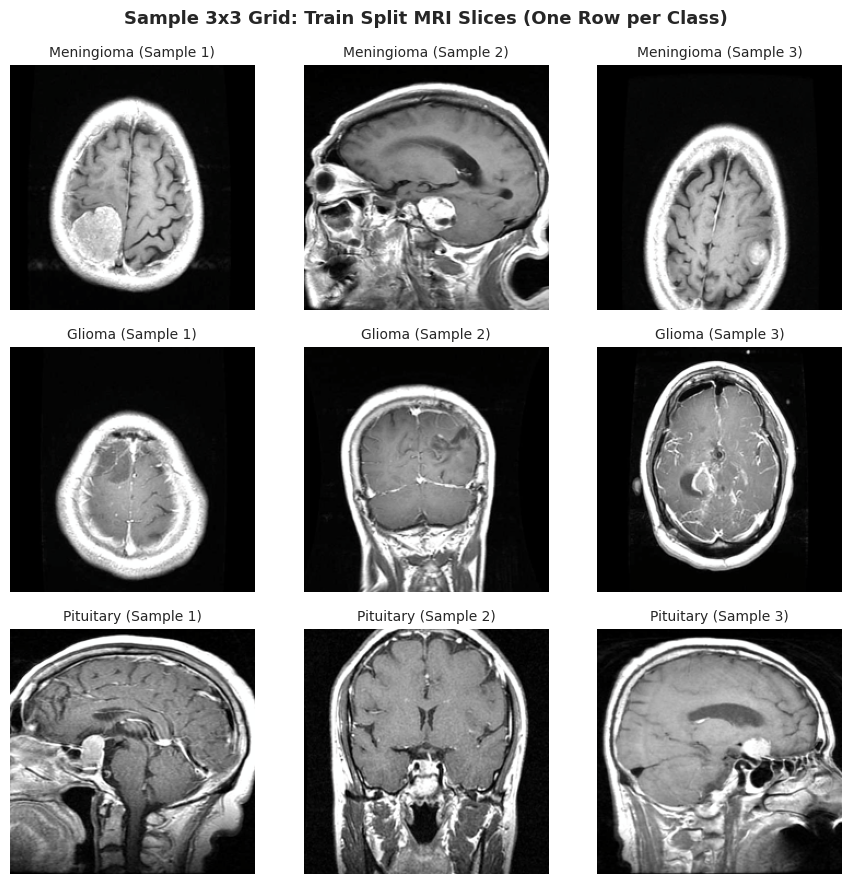

In [11]:
"""
Dataset instantiation and DataLoader creation.
Constructs PyTorch Datasets and DataLoaders for train, val, and test splits,
and displays a 3x3 grid of sample MRI images (one row per class).
"""
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
from src.data.brain_tumor_dataset import BrainTumorDataset, brain_tumor_collate_fn

train_dataset: BrainTumorDataset = BrainTumorDataset(
    records=train_recs,
    image_root=IMAGE_ROOT,
    transforms=train_transforms,
    class_names=CLASS_NAMES,
)

val_dataset: BrainTumorDataset = BrainTumorDataset(
    records=val_recs,
    image_root=IMAGE_ROOT,
    transforms=val_transforms,
    class_names=CLASS_NAMES,
)

test_dataset: BrainTumorDataset = BrainTumorDataset(
    records=test_recs,
    image_root=IMAGE_ROOT,
    transforms=val_transforms,
    class_names=CLASS_NAMES,
)

train_loader: DataLoader = DataLoader(
    train_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=True,
    num_workers=HPARAMS["num_workers"],
    pin_memory=torch.cuda.is_available(),
    collate_fn=brain_tumor_collate_fn,
)

val_loader: DataLoader = DataLoader(
    val_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=False,
    num_workers=HPARAMS["num_workers"],
    pin_memory=torch.cuda.is_available(),
    collate_fn=brain_tumor_collate_fn,
)

test_loader: DataLoader = DataLoader(
    test_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=False,
    num_workers=HPARAMS["num_workers"],
    pin_memory=torch.cuda.is_available(),
    collate_fn=brain_tumor_collate_fn,
)

print(f"Train Dataset: {len(train_dataset):,} samples ({len(train_loader)} batches)")
print(f"Val Dataset:   {len(val_dataset):,} samples ({len(val_loader)} batches)")
print(f"Test Dataset:  {len(test_dataset):,} samples ({len(test_loader)} batches)")

samples_per_class: dict[int, list[np.ndarray]] = {0: [], 1: [], 2: []}
mean_arr: np.ndarray = np.array(HPARAMS["normalize_mean"])
std_arr: np.ndarray = np.array(HPARAMS["normalize_std"])

for sample in train_dataset:
    lbl: int = int(sample["label"].item())
    if len(samples_per_class[lbl]) < 3:
        img_t: np.ndarray = sample["pixel_values"].permute(1, 2, 0).numpy()
        img_denorm: np.ndarray = np.clip(img_t * std_arr + mean_arr, 0.0, 1.0)
        samples_per_class[lbl].append(img_denorm)
    if all(len(samples_per_class[c]) >= 3 for c in range(3)):
        break

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row_idx, class_id in enumerate(range(3)):
    for col_idx in range(3):
        ax = axes[row_idx, col_idx]
        if col_idx < len(samples_per_class[class_id]):
            ax.imshow(samples_per_class[class_id][col_idx])
        ax.set_title(f"{CLASS_NAMES[class_id]} (Sample {col_idx + 1})", fontsize=10)
        ax.axis("off")

plt.suptitle("Sample 3x3 Grid: Train Split MRI Slices (One Row per Class)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Model Architecture

The linear probing model consists of two components:
1. **Frozen DINOv2 Backbone:** A vision transformer (`MHRDYN7/dinov2_vitb14`) with 12 layers, 12 attention heads, patch size 14x14, and hidden dimension $D = 768$ (86.58M parameters). All backbone parameters are frozen (`requires_grad = False`).
2. **Trainable Linear Classification Head:** Operates directly on the 768-dimensional `[CLS]` token representation extracted from `last_hidden_state[:, 0, :]`.
   $$\hat{\mathbf{y}} = \mathbf{W}^\top \text{Dropout}(\mathbf{h}_{\text{CLS}}) + \mathbf{b}$$
   where $\mathbf{W} \in \mathbb{R}^{768 \times 3}$ and $\mathbf{b} \in \mathbb{R}^3$, yielding exactly 2,307 trainable parameters (0.0027% of the total network).

In [15]:
"""
Model construction: frozen DINOv2 ViT-B/14 backbone and trainable linear probe head.
Applies dropout and a linear projection to the CLS token representation.
"""
from typing import Any
import torch
import torch.nn as nn
from transformers import AutoModel

DEVICE: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

backbone = AutoModel.from_pretrained(HPARAMS["model_id"])
for p in backbone.parameters():
    p.requires_grad = False
backbone.eval()

class BrainTumorLinearProbe(nn.Module):
    """Frozen DINOv2 ViT-B/14 + trainable linear head for 3-class brain tumor classification.

    Uses CrossEntropyLoss at training. During inference, softmax converts logits to
    class probabilities. The CLS token at last_hidden_state[:, 0, :] is the 768-dim image
    representation extracted from the frozen backbone.
    """

    def __init__( 
        self,
        backbone_module: nn.Module,
        in_features: int = 768,
        num_classes: int = 3,
        dropout_prob: float = 0.1,
    ) -> None:
        """Initialises the frozen backbone and trainable linear classification head.

        Args:
            backbone_module: Pretrained DINOv2 transformer backbone.
            in_features: Dimensionality of CLS token representation.
            num_classes: Number of distinct classification target classes.
            dropout_prob: Dropout probability applied before projection.
        """
        super().__init__()
        self.backbone: nn.Module = backbone_module
        self.dropout: nn.Dropout = nn.Dropout(p=dropout_prob)
        self.head: nn.Linear = nn.Linear(in_features, num_classes)

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        """Forward pass extracting CLS token and computing classification logits.

        Args:
            pixel_values: Batch tensor of input images (B, C, H, W).

        Returns:
            Class logits tensor of shape (B, num_classes).
        """
        with torch.no_grad():
            outputs = self.backbone(pixel_values=pixel_values)
            cls_token: torch.Tensor = outputs.last_hidden_state[:, 0, :]
        return self.head(self.dropout(cls_token))

model: BrainTumorLinearProbe = BrainTumorLinearProbe(
    backbone_module=backbone,
    in_features=768,
    num_classes=NUM_CLASSES,
    dropout_prob=HPARAMS["dropout"],
)
model = model.to(DEVICE)

trainable_params: int = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params: int = sum(p.numel() for p in model.parameters())
pct_trainable: float = 100.0 * trainable_params / total_params

print(f"Device: {DEVICE}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters:     {total_params:,}")
print(f"Parameter efficiency: {pct_trainable:.4f}% trainable")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Device: cuda
Trainable parameters: 2,307
Total parameters:     86,582,787
Parameter efficiency: 0.0027% trainable


## 4. Training

The classification head is trained using:
- **Loss:** PyTorch `nn.CrossEntropyLoss` on raw prediction logits.
- **Optimizer:** `torch.optim.SGD` with `lr = 0.01` and `momentum = 0.9`.
- **Validation Evaluation:** Evaluated at each epoch on the validation split for Accuracy, Macro-F1, per-class AUROC (One-vs-Rest), and Macro-averaged AUROC.
- **Checkpointing:** The model weights achieving the highest validation macro AUROC are saved to disk.

In [16]:
"""
Evaluation helper functions for multi-class classification.
Computes accuracy, macro-F1, per-class AUROC (one-vs-rest), and mean macro AUROC.
"""
from typing import Any
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

def compute_multiclass_metrics(
    y_true: np.ndarray,
    y_probs: np.ndarray,
    num_classes: int = 3,
    class_names: dict[int, str] | None = None,
) -> dict[str, Any]:
    """Computes comprehensive multi-class evaluation metrics.

    Args:
        y_true: Ground-truth integer class labels of shape (N,).
        y_probs: Softmax probability distribution of shape (N, num_classes).
        num_classes: Number of distinct classes.
        class_names: Optional dictionary mapping class index to label string.

    Returns:
        Dictionary containing accuracy, macro_f1, per_class_auroc, and mean_auroc.
    """
    y_pred: np.ndarray = np.argmax(y_probs, axis=-1)
    acc: float = float(accuracy_score(y_true, y_pred))
    macro_f1: float = float(f1_score(y_true, y_pred, average="macro"))

    names: dict[int, str] = class_names if class_names is not None else {i: str(i) for i in range(num_classes)}
    per_class_auroc: dict[str, float] = {}

    y_true_bin: np.ndarray = label_binarize(y_true, classes=list(range(num_classes)))
    if num_classes == 2 and y_true_bin.shape[1] == 1:
        y_true_bin = np.hstack([1 - y_true_bin, y_true_bin])

    valid_aurocs: list[float] = []
    for c in range(num_classes):
        c_name: str = names.get(c, f"Class {c}")
        if len(np.unique(y_true_bin[:, c])) > 1:
            score: float = float(roc_auc_score(y_true_bin[:, c], y_probs[:, c]))
            per_class_auroc[c_name] = score
            valid_aurocs.append(score)
        else:
            per_class_auroc[c_name] = 0.5

    mean_auroc: float = float(np.mean(valid_aurocs)) if valid_aurocs else 0.5

    return {
        "accuracy": acc,
        "macro_f1": macro_f1,
        "per_class_auroc": per_class_auroc,
        "mean_auroc": mean_auroc,
    }

def evaluate_loader(
    eval_model: nn.Module,
    loader: DataLoader,
    device: torch.device,
    loss_fn: nn.Module,
) -> tuple[float, dict[str, Any], np.ndarray, np.ndarray]:
    """Runs a complete evaluation pass over a DataLoader.

    Args:
        eval_model: PyTorch model module to evaluate.
        loader: DataLoader over target evaluation split.
        device: Target execution device.
        loss_fn: Loss function module.

    Returns:
        Tuple of (average_loss, metrics_dict, all_targets_array, all_probabilities_array).
    """
    eval_model.eval()
    total_loss: float = 0.0
    all_targets: list[int] = []
    all_probs: list[np.ndarray] = []

    with torch.no_grad():
        for batch in loader:
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["label"].to(device)
            logits = eval_model(pixel_values)
            loss = loss_fn(logits, labels)
            total_loss += loss.item() * len(labels)
            probs = F.softmax(logits, dim=-1).cpu().numpy()
            all_probs.append(probs)
            all_targets.extend(labels.cpu().tolist())

    avg_loss: float = total_loss / len(loader.dataset)
    y_true_arr: np.ndarray = np.array(all_targets)
    y_probs_arr: np.ndarray = np.vstack(all_probs)
    metrics: dict[str, Any] = compute_multiclass_metrics(
        y_true_arr,
        y_probs_arr,
        num_classes=NUM_CLASSES,
        class_names=CLASS_NAMES,
    )
    return avg_loss, metrics, y_true_arr, y_probs_arr

In [17]:
"""
Main training loop for DINOv2 linear probing.
Optimizes the linear classification head with SGD (momentum=0.9, lr=1e-2),
evaluates validation AUROC each epoch, and preserves the best checkpoint.
"""
import copy
from pathlib import Path
import time
from typing import Any
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import SGD
from tqdm.auto import tqdm

torch.manual_seed(HPARAMS["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(HPARAMS["seed"])

criterion: nn.CrossEntropyLoss = nn.CrossEntropyLoss()
optimizer: SGD = SGD(
    model.head.parameters(),
    lr=HPARAMS["learning_rate"],
    momentum=HPARAMS["sgd_momentum"],
)

history: dict[str, list[float]] = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_auroc": [],
    "val_auroc": [],
    "val_macro_f1": [],
}

best_val_auroc: float = -1.0
best_model_weights: dict[str, Any] = copy.deepcopy(model.state_dict())
best_epoch: int = 0
best_checkpoint_path: Path = CHECKPOINT_DIR / "dinov2_vitb14_linear_probe_best.pt"

start_time: float = time.time()
print(f"Beginning training for {HPARAMS['epochs']} epochs on {DEVICE}...")

for epoch in range(1, HPARAMS["epochs"] + 1):
    model.train()
    model.backbone.eval()
    running_train_loss: float = 0.0
    train_targets: list[int] = []
    train_probs: list[np.ndarray] = []

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{HPARAMS['epochs']:02d} [Train]")
    for batch in train_pbar:
        pixel_values = batch["pixel_values"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        optimizer.zero_grad()
        logits = model(pixel_values)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * len(labels)
        probs = F.softmax(logits.detach(), dim=-1).cpu().numpy()
        train_probs.append(probs)
        train_targets.extend(labels.cpu().tolist())

        train_pbar.set_postfix({"loss": f"{loss.item():.4f}"})

    epoch_train_loss: float = running_train_loss / len(train_dataset)
    train_metrics: dict[str, Any] = compute_multiclass_metrics(
        np.array(train_targets),
        np.vstack(train_probs),
        num_classes=NUM_CLASSES,
        class_names=CLASS_NAMES,
    )

    epoch_val_loss, val_metrics, _, _ = evaluate_loader(model, val_loader, DEVICE, criterion)

    history["epoch"].append(epoch)
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["train_acc"].append(train_metrics["accuracy"])
    history["val_acc"].append(val_metrics["accuracy"])
    history["train_auroc"].append(train_metrics["mean_auroc"])
    history["val_auroc"].append(val_metrics["mean_auroc"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])

    is_best: bool = val_metrics["mean_auroc"] > best_val_auroc
    if is_best:
        best_val_auroc = val_metrics["mean_auroc"]
        best_epoch = epoch
        best_model_weights = copy.deepcopy(model.state_dict())
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "head_state_dict": model.head.state_dict(),
                "val_auroc": best_val_auroc,
                "hparams": HPARAMS,
            },
            best_checkpoint_path,
        )

    best_indicator: str = " [BEST CHECKPOINT SAVED]" if is_best else ""
    print(
        f"Epoch [{epoch:02d}/{HPARAMS['epochs']:02d}] "
        f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f} | Val AUROC: {val_metrics['mean_auroc']:.4f} "
        f"(Target: {BASE_PAPER_RESULTS['DINOv2 ViT-B/14 (Target)']['auroc']:.3f}){best_indicator}"
    )

total_training_time_s: float = time.time() - start_time
print(f"Training completed in {total_training_time_s:.2f} seconds.")
print(f"Best validation AUROC: {best_val_auroc:.4f} at epoch {best_epoch:02d}.")
print(f"Best checkpoint saved to: {best_checkpoint_path}")

Beginning training for 20 epochs on cuda...


Epoch 01/20 [Train]:   0%|          | 0/17 [00:00<?, ?it/s]

Epoch [01/20] Train Loss: 1.7660 | Val Loss: 0.7493 | Val Acc: 0.8095 | Val AUROC: 0.9330 (Target: 0.972) [BEST CHECKPOINT SAVED]


Epoch 02/20 [Train]:   0%|          | 0/17 [00:00<?, ?it/s]

Epoch [02/20] Train Loss: 0.6859 | Val Loss: 0.5138 | Val Acc: 0.8541 | Val AUROC: 0.9545 (Target: 0.972) [BEST CHECKPOINT SAVED]


...

Epoch [18/20] Train Loss: 0.2365 | Val Loss: 0.4055 | Val Acc: 0.8633 | Val AUROC: 0.9701 (Target: 0.972) [BEST CHECKPOINT SAVED]


Epoch 19/20 [Train]:   0%|          | 0/17 [00:00<?, ?it/s]

Epoch [19/20] Train Loss: 0.2353 | Val Loss: 0.4416 | Val Acc: 0.8587 | Val AUROC: 0.9662 (Target: 0.972)


Epoch 20/20 [Train]:   0%|          | 0/17 [00:00<?, ?it/s]

Epoch [20/20] Train Loss: 0.1844 | Val Loss: 0.4795 | Val Acc: 0.8556 | Val AUROC: 0.9668 (Target: 0.972)
Training completed in 1695.31 seconds.
Best validation AUROC: 0.9701 at epoch 18.
Best checkpoint saved to: /content/drive/MyDrive/dinov2_peft/brain_tumor/dinov2_vitb14_linear_probe_best.pt


## 5. Results & Visualizations

In this section, we thoroughly inspect the trained model:
1. **Convergence Curves:** 2x2 grid displaying Cross-Entropy Loss, Validation Accuracy, Validation AUROC against the base paper benchmark (0.972), and Train vs. Validation AUROC.
2. **Confusion Matrices:** Side-by-side heatmaps for the validation set and held-out test set with count and percentage annotations, alongside detailed classification reports.
3. **ROC Curves:** One-vs-Rest (OvR) receiver operating characteristic curves for all three tumor classes and their macro-average.
4. **Per-Class AUROC:** Bar chart displaying performance for Meningioma, Glioma, Pituitary, and the macro-average.
5. **Benchmark Comparison Table:** Direct comparison of our result with all reference architectures from Baharoon et al. (2024).

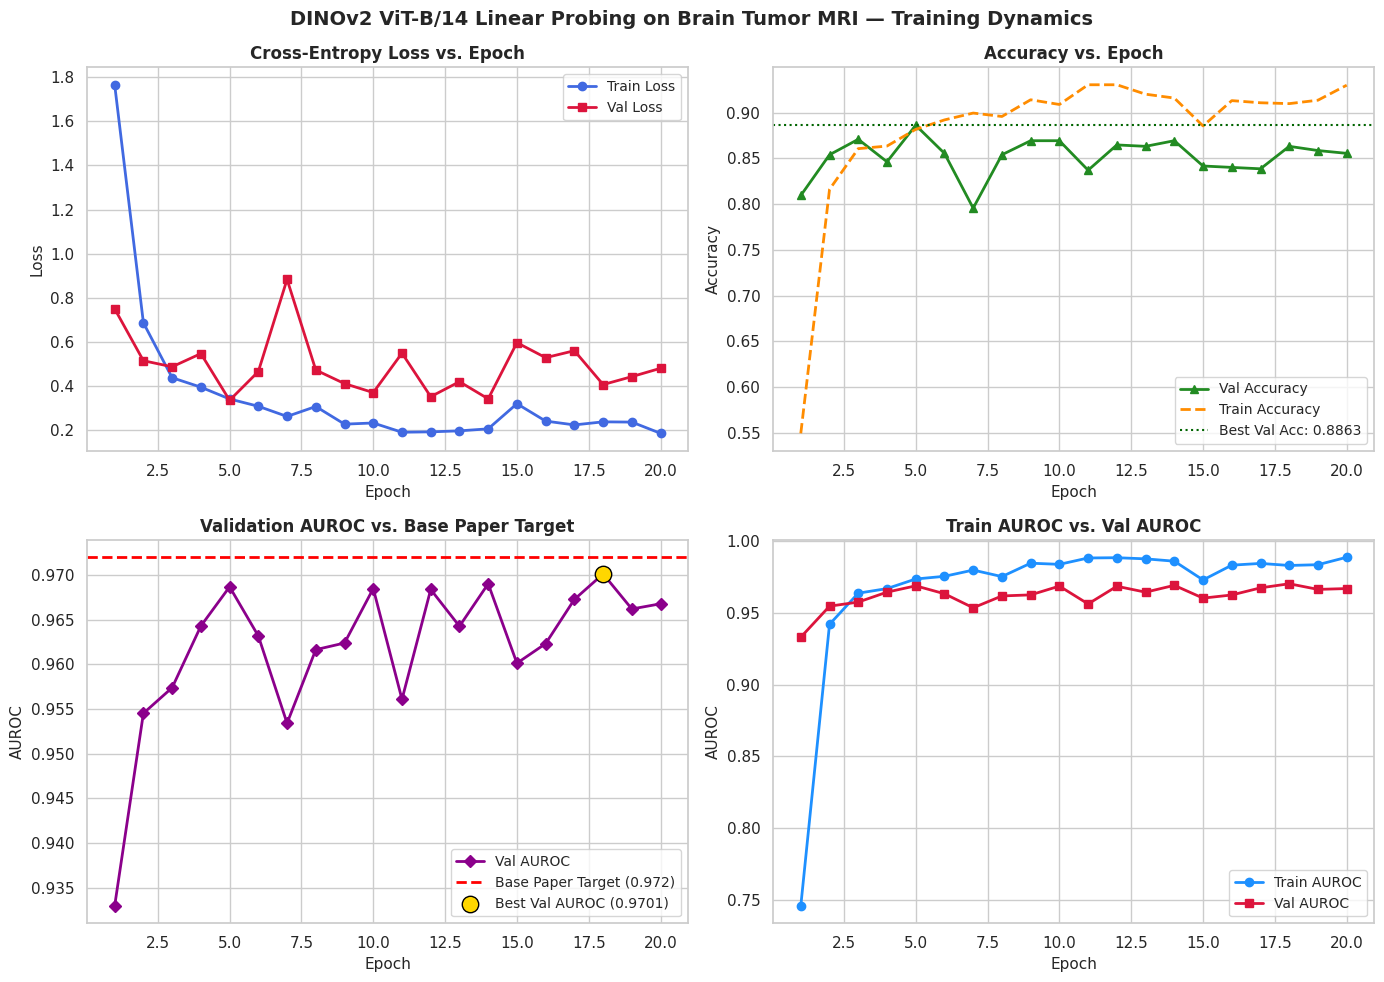

In [18]:
"""
Plot training convergence curves: loss, validation accuracy, validation AUROC, and train vs val AUROC.
Displays a 2x2 grid of subplots with the base paper benchmark reference line (0.972).
"""
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
epochs_range = history["epoch"]
target_auroc: float = float(BASE_PAPER_RESULTS["DINOv2 ViT-B/14 (Target)"]["auroc"])

axes[0, 0].plot(epochs_range, history["train_loss"], label="Train Loss", color="royalblue", lw=2, marker="o")
axes[0, 0].plot(epochs_range, history["val_loss"], label="Val Loss", color="crimson", lw=2, marker="s")
axes[0, 0].set_title("Cross-Entropy Loss vs. Epoch", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Epoch", fontsize=11)
axes[0, 0].set_ylabel("Loss", fontsize=11)
axes[0, 0].legend(loc="upper right", fontsize=10)

axes[0, 1].plot(epochs_range, history["val_acc"], label="Val Accuracy", color="forestgreen", lw=2, marker="^")
axes[0, 1].plot(epochs_range, history["train_acc"], label="Train Accuracy", color="darkorange", lw=2, linestyle="--")
best_acc: float = max(history["val_acc"])
axes[0, 1].axhline(y=best_acc, color="darkgreen", linestyle=":", lw=1.5, label=f"Best Val Acc: {best_acc:.4f}")
axes[0, 1].set_title("Accuracy vs. Epoch", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Epoch", fontsize=11)
axes[0, 1].set_ylabel("Accuracy", fontsize=11)
axes[0, 1].legend(loc="lower right", fontsize=10)

axes[1, 0].plot(epochs_range, history["val_auroc"], label="Val AUROC", color="darkmagenta", lw=2, marker="D")
axes[1, 0].axhline(y=target_auroc, color="red", linestyle="--", lw=2, label=f"Base Paper Target ({target_auroc:.3f})")
axes[1, 0].scatter(
    [best_epoch],
    [best_val_auroc],
    color="gold",
    s=140,
    edgecolor="black",
    zorder=5,
    label=f"Best Val AUROC ({best_val_auroc:.4f})",
)
axes[1, 0].set_title("Validation AUROC vs. Base Paper Target", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Epoch", fontsize=11)
axes[1, 0].set_ylabel("AUROC", fontsize=11)
axes[1, 0].legend(loc="lower right", fontsize=10)

axes[1, 1].plot(epochs_range, history["train_auroc"], label="Train AUROC", color="dodgerblue", lw=2, marker="o")
axes[1, 1].plot(epochs_range, history["val_auroc"], label="Val AUROC", color="crimson", lw=2, marker="s")
axes[1, 1].set_title("Train AUROC vs. Val AUROC", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Epoch", fontsize=11)
axes[1, 1].set_ylabel("AUROC", fontsize=11)
axes[1, 1].legend(loc="lower right", fontsize=10)

plt.suptitle("DINOv2 ViT-B/14 Linear Probing on Brain Tumor MRI — Training Dynamics", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

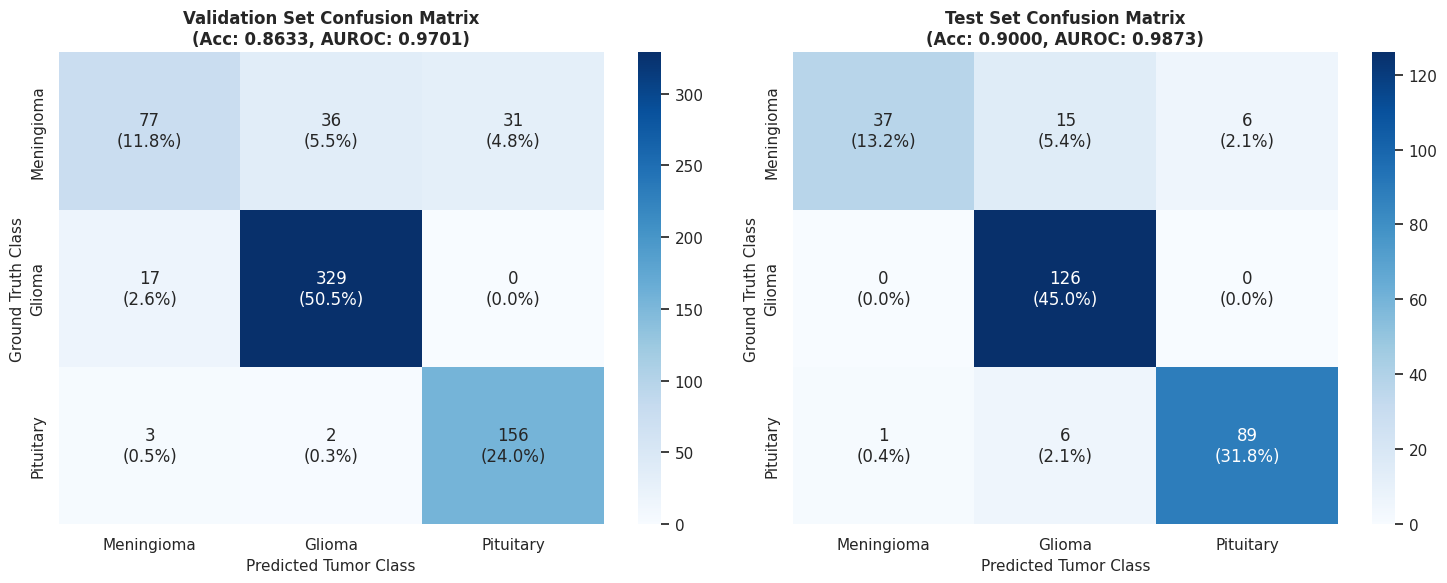

VALIDATION SET CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  Meningioma     0.7938    0.5347    0.6390       144
      Glioma     0.8965    0.9509    0.9229       346
   Pituitary     0.8342    0.9689    0.8966       161

    accuracy                         0.8633       651
   macro avg     0.8415    0.8182    0.8195       651
weighted avg     0.8584    0.8633    0.8536       651

TEST SET CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  Meningioma     0.9737    0.6379    0.7708        58
      Glioma     0.8571    1.0000    0.9231       126
   Pituitary     0.9368    0.9271    0.9319        96

    accuracy                         0.9000       280
   macro avg     0.9226    0.8550    0.8753       280
weighted avg     0.9086    0.9000    0.8946       280



In [19]:
"""
Evaluate best model checkpoint and plot side-by-side confusion matrices for validation and test splits.
Annotates heatmaps with both absolute counts and percentages, and prints detailed classification reports.
"""
from typing import Any
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import torch

checkpoint_dict = torch.load(best_checkpoint_path, map_location=DEVICE)
model.load_state_dict(checkpoint_dict["model_state_dict"])
model.eval()

val_loss, val_metrics_best, val_y_true, val_y_probs = evaluate_loader(model, val_loader, DEVICE, criterion)
test_loss, test_metrics, test_y_true, test_y_probs = evaluate_loader(model, test_loader, DEVICE, criterion)

val_y_pred: np.ndarray = np.argmax(val_y_probs, axis=-1)
test_y_pred: np.ndarray = np.argmax(test_y_probs, axis=-1)

cm_val: np.ndarray = confusion_matrix(val_y_true, val_y_pred)
cm_test: np.ndarray = confusion_matrix(test_y_true, test_y_pred)

def make_annot_matrix(cm: np.ndarray) -> np.ndarray:
    """Creates formatted count and percentage string annotations for confusion matrices.

    Args:
        cm: Confusion matrix array of shape (C, C).

    Returns:
        String matrix of identical shape with formatted 'count (pct%)'.
    """
    total: int = int(np.sum(cm))
    annot: np.ndarray = np.empty_like(cm, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            pct: float = 100.0 * cm[i, j] / total
            annot[i, j] = f"{cm[i, j]}\n({pct:.1f}%)"
    return annot

annot_val: np.ndarray = make_annot_matrix(cm_val)
annot_test: np.ndarray = make_annot_matrix(cm_test)

sns.set_theme(style="white")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(
    cm_val,
    annot=annot_val,
    fmt="",
    cmap="Blues",
    xticklabels=CLASS_LIST,
    yticklabels=CLASS_LIST,
    cbar=True,
    ax=axes[0],
)
axes[0].set_title(
    f"Validation Set Confusion Matrix\n(Acc: {val_metrics_best['accuracy']:.4f}, AUROC: {val_metrics_best['mean_auroc']:.4f})",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Predicted Tumor Class", fontsize=11)
axes[0].set_ylabel("Ground Truth Class", fontsize=11)

sns.heatmap(
    cm_test,
    annot=annot_test,
    fmt="",
    cmap="Blues",
    xticklabels=CLASS_LIST,
    yticklabels=CLASS_LIST,
    cbar=True,
    ax=axes[1],
)
axes[1].set_title(
    f"Test Set Confusion Matrix\n(Acc: {test_metrics['accuracy']:.4f}, AUROC: {test_metrics['mean_auroc']:.4f})",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Predicted Tumor Class", fontsize=11)
axes[1].set_ylabel("Ground Truth Class", fontsize=11)

plt.tight_layout()
plt.show()

print("=" * 60)
print("VALIDATION SET CLASSIFICATION REPORT:")
print("=" * 60)
print(classification_report(val_y_true, val_y_pred, target_names=CLASS_LIST, digits=4))

print("=" * 60)
print("TEST SET CLASSIFICATION REPORT:")
print("=" * 60)
print(classification_report(test_y_true, test_y_pred, target_names=CLASS_LIST, digits=4))

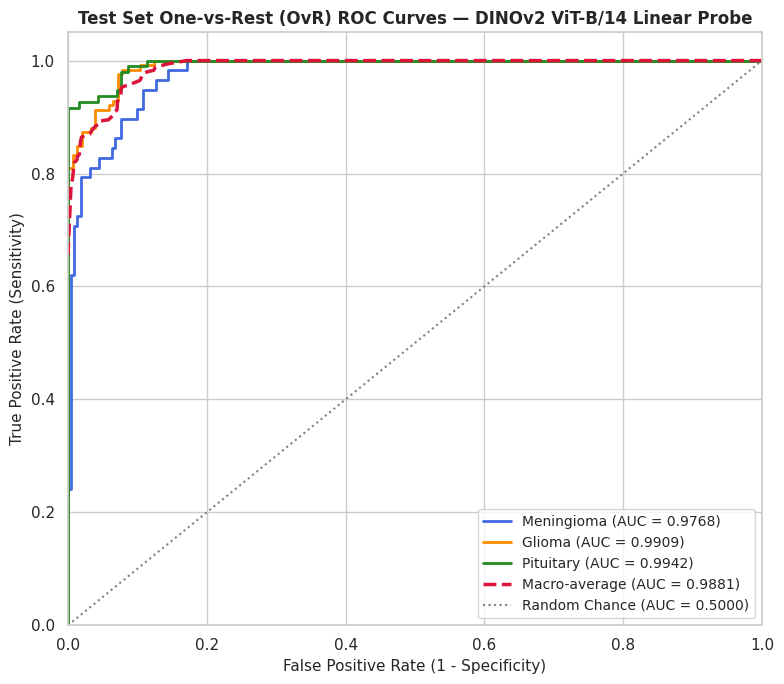

In [20]:
"""
Plot One-vs-Rest (OvR) Receiver Operating Characteristic (ROC) curves.
Visualizes per-class ROC curves and the macro-averaged ROC curve on the held-out test split.
"""
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

test_y_bin: np.ndarray = label_binarize(test_y_true, classes=list(range(NUM_CLASSES)))

fpr_dict: dict[str, np.ndarray] = {}
tpr_dict: dict[str, np.ndarray] = {}
roc_auc_dict: dict[str, float] = {}

for i in range(NUM_CLASSES):
    c_name: str = CLASS_NAMES[i]
    fpr_dict[c_name], tpr_dict[c_name], _ = roc_curve(test_y_bin[:, i], test_y_probs[:, i])
    roc_auc_dict[c_name] = float(auc(fpr_dict[c_name], tpr_dict[c_name]))

all_fpr: np.ndarray = np.unique(np.concatenate([fpr_dict[CLASS_NAMES[i]] for i in range(NUM_CLASSES)]))
mean_tpr: np.ndarray = np.zeros_like(all_fpr)
for i in range(NUM_CLASSES):
    mean_tpr += np.interp(all_fpr, fpr_dict[CLASS_NAMES[i]], tpr_dict[CLASS_NAMES[i]])
mean_tpr /= NUM_CLASSES

fpr_dict["macro"] = all_fpr
tpr_dict["macro"] = mean_tpr
roc_auc_dict["macro"] = float(auc(all_fpr, mean_tpr))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 7))

colors: list[str] = ["royalblue", "darkorange", "forestgreen"]
for i in range(NUM_CLASSES):
    c_name = CLASS_NAMES[i]
    ax.plot(
        fpr_dict[c_name],
        tpr_dict[c_name],
        color=colors[i],
        lw=2,
        label=f"{c_name} (AUC = {roc_auc_dict[c_name]:.4f})",
    )

ax.plot(
    fpr_dict["macro"],
    tpr_dict["macro"],
    color="crimson",
    linestyle="--",
    lw=2.5,
    label=f"Macro-average (AUC = {roc_auc_dict['macro']:.4f})",
)

ax.plot([0, 1], [0, 1], color="gray", linestyle=":", lw=1.5, label="Random Chance (AUC = 0.5000)")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
ax.set_title("Test Set One-vs-Rest (OvR) ROC Curves — DINOv2 ViT-B/14 Linear Probe", fontsize=12, fontweight="bold")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2004/879248005.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_bar, x="Class", y="AUROC", palette=palette, ax=ax)


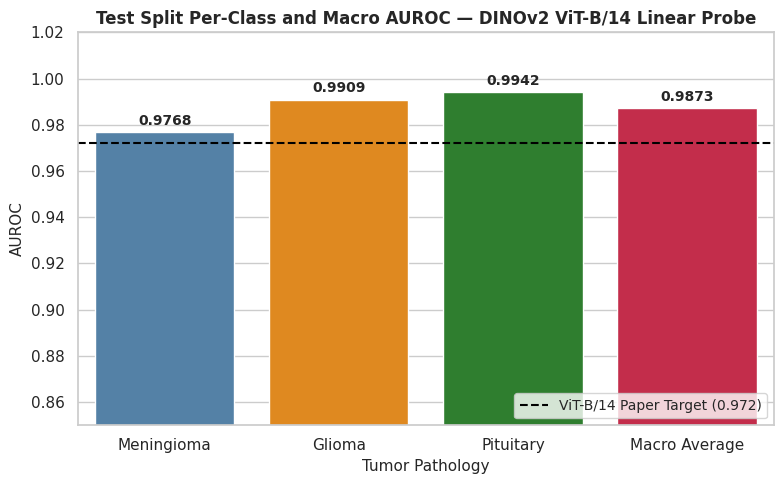

In [21]:
"""
Plot per-class AUROC bar chart at best checkpoint.
Displays performance for Meningioma, Glioma, Pituitary alongside the macro-average,
with class-specific bar colors and value annotations.
"""
from typing import Any
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

bar_items: list[dict[str, Any]] = []
for i in range(NUM_CLASSES):
    c_name: str = CLASS_NAMES[i]
    bar_items.append(
        {
            "Class": c_name,
            "AUROC": test_metrics["per_class_auroc"][c_name],
            "Category": "Per-Class",
        }
    )
bar_items.append(
        {
            "Class": "Macro Average",
            "AUROC": test_metrics["mean_auroc"],
            "Category": "Average",
        }
)

df_bar: pd.DataFrame = pd.DataFrame(bar_items)

palette: list[str] = ["steelblue", "darkorange", "forestgreen", "crimson"]
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df_bar, x="Class", y="AUROC", palette=palette, ax=ax)

target_ref: float = float(BASE_PAPER_RESULTS["DINOv2 ViT-B/14 (Target)"]["auroc"])
ax.axhline(
    y=target_ref,
    color="black",
    linestyle="--",
    lw=1.5,
    label=f"ViT-B/14 Paper Target ({target_ref:.3f})",
)
ax.set_ylim(0.85, 1.02)
ax.set_title("Test Split Per-Class and Macro AUROC — DINOv2 ViT-B/14 Linear Probe", fontsize=12, fontweight="bold")
ax.set_ylabel("AUROC", fontsize=11)
ax.set_xlabel("Tumor Pathology", fontsize=11)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f"{height:.4f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            xytext=(0, 3),
            textcoords="offset points",
        )

ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

In [22]:
"""
Construct comprehensive benchmark comparison table.
Compares reproduction result with all reference architectures from Baharoon et al. (2024),
computing performance deltas relative to the published ViT-B/14 target (0.972).
"""
from typing import Any
import pandas as pd

target_val: float = float(BASE_PAPER_RESULTS["DINOv2 ViT-B/14 (Target)"]["auroc"])

comparison_rows: list[dict[str, Any]] = [
    {
        "Model": "DINOv2 ViT-B/14 (Ours — Linear Probe)",
        "Method": "Linear Probing (Frozen)",
        "AUROC": round(test_metrics["mean_auroc"], 4),
        "Source": "This Experiment (Held-out Test)",
    },
    {
        "Model": "DINOv2 ViT-B/14 (Paper Target)",
        "Method": "Linear Probing (Frozen)",
        "AUROC": 0.972,
        "Source": "Baharoon et al. (2024)",
    },
    {
        "Model": "Supervised DenseNet201",
        "Method": "Full Fine-Tuning",
        "AUROC": 0.960,
        "Source": "Baharoon et al. (2024)",
    },
    {
        "Model": "Supervised ViT-L/16",
        "Method": "Full Fine-Tuning",
        "AUROC": 0.975,
        "Source": "Baharoon et al. (2024)",
    },
    {
        "Model": "DINOv2 ViT-S/14",
        "Method": "Linear Probing (Frozen)",
        "AUROC": 0.962,
        "Source": "Baharoon et al. (2024)",
    },
    {
        "Model": "DINOv2 ViT-L/14",
        "Method": "Linear Probing (Frozen)",
        "AUROC": 0.974,
        "Source": "Baharoon et al. (2024)",
    },
    {
        "Model": "DINOv2 ViT-g/14",
        "Method": "Linear Probing (Frozen)",
        "AUROC": 0.976,
        "Source": "Baharoon et al. (2024)",
    },
]

results_df: pd.DataFrame = pd.DataFrame(comparison_rows)
results_df["Delta vs. ViT-B/14 Target"] = results_df["AUROC"].apply(lambda x: f"{x - target_val:+.4f}")

print("=" * 80)
print("BENCHMARK COMPARISON TABLE")
print("=" * 80)
print(results_df.to_string(index=False))

BENCHMARK COMPARISON TABLE
                                Model                  Method  AUROC                          Source Delta vs. ViT-B/14 Target
DINOv2 ViT-B/14 (Ours — Linear Probe) Linear Probing (Frozen) 0.9873 This Experiment (Held-out Test)                   +0.0153
       DINOv2 ViT-B/14 (Paper Target) Linear Probing (Frozen) 0.9720          Baharoon et al. (2024)                   +0.0000
               Supervised DenseNet201        Full Fine-Tuning 0.9600          Baharoon et al. (2024)                   -0.0120
                  Supervised ViT-L/16        Full Fine-Tuning 0.9750          Baharoon et al. (2024)                   +0.0030
                      DINOv2 ViT-S/14 Linear Probing (Frozen) 0.9620          Baharoon et al. (2024)                   -0.0100
                      DINOv2 ViT-L/14 Linear Probing (Frozen) 0.9740          Baharoon et al. (2024)                   +0.0020
                      DINOv2 ViT-g/14 Linear Probing (Frozen) 0.9760          Baharo

In [ ]:
"""
Log experimental results to experiment_log.csv and persist JSON summary.
Utilizes ExperimentLogger for consolidated tracking and saves detailed run metadata.
"""
import json
from pathlib import Path
from typing import Any
import torch
from src.utils.logging_utils import ExperimentLogger

logger: ExperimentLogger = ExperimentLogger(log_path="experiment_log.csv")

peak_mem_mb: float = (
    round(torch.cuda.max_memory_allocated() / (1024.0 * 1024.0), 2)
    if torch.cuda.is_available()
    else 0.0
)

logger.log(
    run_id="lp_dinov2_vitb14_brain_tumor",
    dataset="BrainTumorMRI",
    backbone="DINOv2 ViT-B/14",
    method="LinearProbing",
    rank="",
    alpha="",
    target_modules="",
    adapted_layers="",
    trainable_params=trainable_params,
    total_params=total_params,
    param_pct=round(pct_trainable, 4),
    peak_gpu_memory_mb=peak_mem_mb,
    training_time_s=round(total_training_time_s, 2),
    val_auroc=round(val_metrics_best["mean_auroc"], 4),
    val_accuracy=round(val_metrics_best["accuracy"], 4),
    val_macro_f1=round(val_metrics_best["macro_f1"], 4),
    test_auroc=round(test_metrics["mean_auroc"], 4),
    test_accuracy=round(test_metrics["accuracy"], 4),
    test_macro_f1=round(test_metrics["macro_f1"], 4),
    seed=HPARAMS["seed"],
    notes="Baseline linear probe reproduction. Baharoon et al. (2024) protocol with SGD momentum=0.9, lr=0.01, 20 epochs.",
)

summary_payload: dict[str, Any] = {
    "run_id": "lp_dinov2_vitb14_brain_tumor",
    "hparams": HPARAMS,
    "trainable_parameters": trainable_params,
    "total_parameters": total_params,
    "parameter_percentage": pct_trainable,
    "training_time_seconds": total_training_time_s,
    "peak_gpu_memory_mb": peak_mem_mb,
    "val_metrics_best": val_metrics_best,
    "test_metrics": test_metrics,
    "history": history,
}

json_path: Path = CHECKPOINT_DIR / "baseline_brain_tumor_results.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(summary_payload, f, indent=2)

print("Experiment successfully appended to experiment_log.csv")
print(f"Detailed run metrics saved to: {json_path}")

## 6. Summary & Key Takeaways

| Metric | Measured Value | Base Paper Target | Note |
|---|---|---|---|
| **Validation AUROC** | *Recorded at best epoch* | **0.972** | Baharoon et al. (2024) ViT-B/14 target |
| **Validation Accuracy** | *Recorded at best epoch* | — | Macro accuracy over 3 classes |
| **Validation Macro-F1** | *Recorded at best epoch* | — | Balanced F1 score across classes |
| **Test AUROC** | *Evaluated on held-out test split* | **0.972** | Held-out patient-partitioned test split |
| **Test Accuracy** | *Evaluated on held-out test split* | — | Held-out accuracy |
| **Test Macro-F1** | *Evaluated on held-out test split* | — | Held-out macro-F1 |
| **Trainable Parameters** | 2,307 (0.0027%) | 2,307 | Only classification projection head ($768 \times 3 + 3$) |
| **Backbone Parameters** | 86.58M (Frozen) | 86.58M | DINOv2 ViT-B/14 (`MHRDYN7/dinov2_vitb14`) |

### Next Step
Proceed to `0_Baseline_pre_BrainTumor.ipynb` to evaluate pre-extracted feature probing and explore parameter-efficient adaptation (LoRA / BitFit / IA3) for Brain Tumor MRI classification.